In [24]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pickle

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior

# Posterior Inference Evaluation

Posterior sampling and analysis for trained neural density estimator.

In [25]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_spline_from_config

## 1. Setup: Imports and Configurations

In [26]:
import yaml

outputs_root = project_root / "outputs"

run_selector = "latest"
# Example explicit selector:
# run_selector = "highnodes/2026-03-16/16-07-10"


def resolve_run_dir(selector: str) -> Path:
    if selector != "latest":
        candidate = (outputs_root / selector).resolve()
        if not candidate.exists():
            raise FileNotFoundError(f"Run directory not found: {candidate}")
        return candidate

    model_candidates = list(outputs_root.rglob("density_estimator.pkl"))
    if not model_candidates:
        raise FileNotFoundError(f"No trained model found below {outputs_root}")
    return max(model_candidates, key=lambda p: p.stat().st_mtime).parent


def load_hydra_cfg(run_dir: Path) -> dict:
    hydra_cfg_path = run_dir / ".hydra" / "config.yaml"
    if not hydra_cfg_path.exists():
        return {}
    return yaml.safe_load(hydra_cfg_path.read_text())


def resolve_data_config(run_dir: Path, hydra_cfg: dict) -> Path:
    copied = run_dir / "data_config.yaml"
    if copied.exists():
        return copied

    data_dir_rel = hydra_cfg.get("data", {}).get("data_dir")
    if data_dir_rel is None:
        raise FileNotFoundError(
            f"Could not resolve data config: missing {copied} and data.data_dir in .hydra/config.yaml"
        )

    fallback = (project_root / data_dir_rel / "config.yaml").resolve()
    if not fallback.exists():
        raise FileNotFoundError(f"Data config not found: {fallback}")
    return fallback


def resolve_model_path(run_dir: Path, hydra_cfg: dict) -> Path:
    model_filename = hydra_cfg.get("artifacts", {}).get("model_filename", "density_estimator.pkl")
    model_path = run_dir / model_filename
    if not model_path.exists():
        raise FileNotFoundError(f"Model file not found: {model_path}")
    return model_path


run_dir = resolve_run_dir(run_selector)
hydra_cfg = load_hydra_cfg(run_dir)
data_cfg = resolve_data_config(run_dir, hydra_cfg)
model_path = resolve_model_path(run_dir, hydra_cfg)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"run_dir  : {run_dir}")
print(f"data_cfg : {data_cfg}")
print(f"model    : {model_path}")
print(f"device   : {device}")

run_dir  : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/2026-03-12/18-34-42
data_cfg : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/data/base/config.yaml
model    : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/2026-03-12/18-34-42/density_estimator.pkl
device   : cuda


## 2. Load Trained Model and Select Run

In [27]:
prior = generate_posterior_prior_from_config(str(data_cfg), device=device)
eval_spline = eval_spline_from_config(str(data_cfg))

## 3. Initialize Prior and Simulator

In [28]:
# ============================================================================
# Sampling and Optimization Configuration
# ============================================================================

config = {
    # Posterior sampling
    "num_posterior_samples": 10000,
    "posterior_batch_size": 1000,
    
    # Log-prob batching (to avoid OOM)
    "log_prob_batch_size": 500,
    
    # MAP estimation
    "map_num_iter": 1_000,
    "map_num_to_optimize": 1,
    "map_learning_rate": 0.01,
    "map_init_method": "posterior",
    "map_num_init_samples": 5,
    "map_save_best_every": 10,
    "map_show_progress_bars": False,
    "map_force_update": False,
}

In [29]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [30]:
fret_simulator = smFRET_simulator_wrapper_from_config(str(data_cfg))

In [31]:
true_params = torch.tensor([ -0.200, 1.0938, 0.0873, .35556,  1.55016, 1.31840,  8.0000, 9.000, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)
true_params1 = torch.tensor([ 0.200, -.0938, -2.0873, 1.35556,  0.1016, 0.6840,  8.0000, 3.000, 0.0100,  0.01000,  0.9500,  0.9500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)

In [32]:
prior.log_prob(true_params[:6].to(device)), prior.log_prob(true_params1[:6].to(device))

(tensor([-11.1971], device='cuda:0'), tensor([-11.5148], device='cuda:0'))

(-5.0, 5.0)

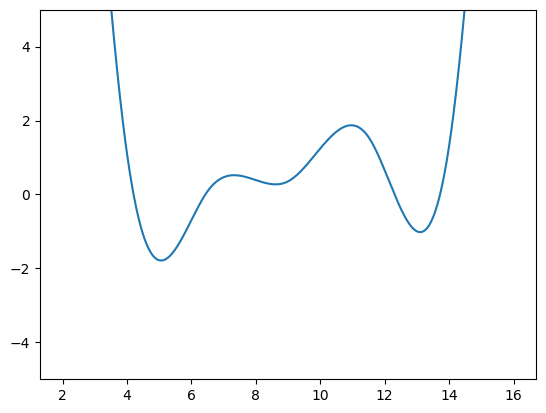

In [33]:
x, y = eval_spline(
    params=true_params,
    x_eval=np.linspace(2, 16, 1000),
    N_knots=5,
    x_min=4,
    x_max=14,
    boundary_condition='bound',
    max_G0=30,
    spline_type="cubic"
)
plt.plot(x, y)
plt.ylim(-5, 5)

In [34]:
observation = torch.stack([fret_simulator(true_params) for _ in range(1)])

## 4. Create Test Observation

In [35]:
observation.sum()

tensor(85695.)

Text(0.5, 0, 'Time')

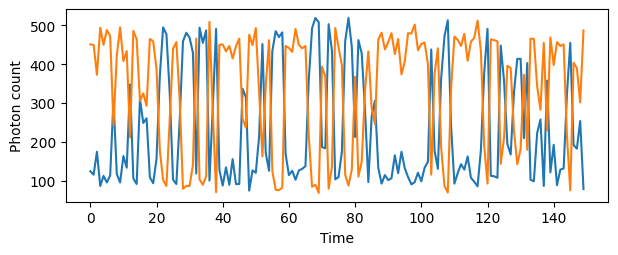

In [36]:
idx = 0
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[idx, :,0].numpy(), n_bins=150), label="Donor")
plt.plot(bin_along_time(observation[idx, :,1].numpy(), n_bins=150), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")

In [37]:
with open(model_path, "rb") as f:
    density_estimator = pickle.load(f)
density_estimator = density_estimator.to(device)

## 5. Posterior Inference

In [38]:
posterior = DirectPosterior(density_estimator, prior=prior)
obs = observation.to(device)
samples = posterior.sample(
    (config["num_posterior_samples"],),
    x=obs,
    max_sampling_batch_size=config["posterior_batch_size"]
).cpu()

# Batch log_prob computation to avoid OOM
log_probs_list = []
for i in range(0, samples.shape[0], config["log_prob_batch_size"]):
    batch = samples[i:i+config["log_prob_batch_size"]].to(device)
    log_probs_list.append(
        posterior.log_prob_batched(batch, x=obs, norm_posterior=False).cpu()
    )
log_probs = torch.cat(log_probs_list)

10077it [00:00, 38038.89it/s]                          


In [39]:
posterior.set_default_x(observation.to(device))
map_estimate = posterior.map(
    num_iter=config["map_num_iter"],
    num_to_optimize=config["map_num_to_optimize"],
    learning_rate=config["map_learning_rate"],
    init_method=config["map_init_method"],
    num_init_samples=config["map_num_init_samples"],
    save_best_every=config["map_save_best_every"],
    show_progress_bars=config["map_show_progress_bars"],
    force_update=config["map_force_update"],
)

100%|██████████| 5/5 [00:00<00:00, 139.21it/s]


/tmp/ipykernel_1107533/542082884.py:1: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


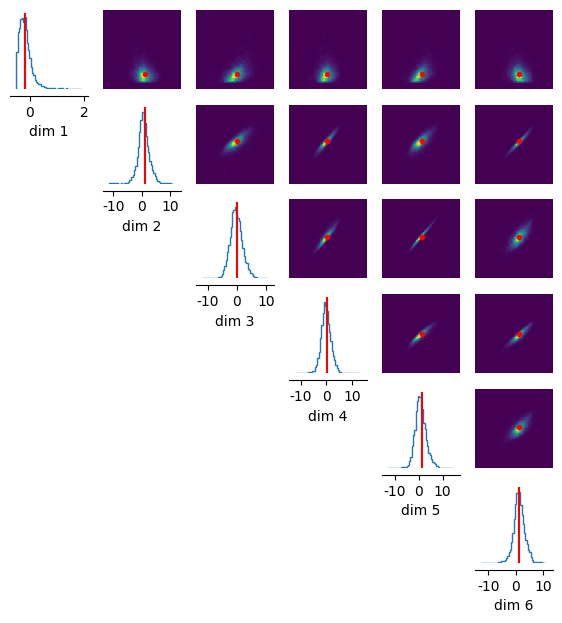

In [40]:
_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=true_params.cpu(),
    points_offdiag={'markersize': 6},
    points_colors='r', 
)

In [41]:
samples[:, 1:] = samples[:, 1:] - samples[:, 1:].mean(dim=1, keepdim=True)
map_estimate[1:] = map_estimate[1:] - map_estimate[1:].mean()
true_params[1:5] = true_params[1:5] - true_params[1:5].mean()

## 6. Analyze Results

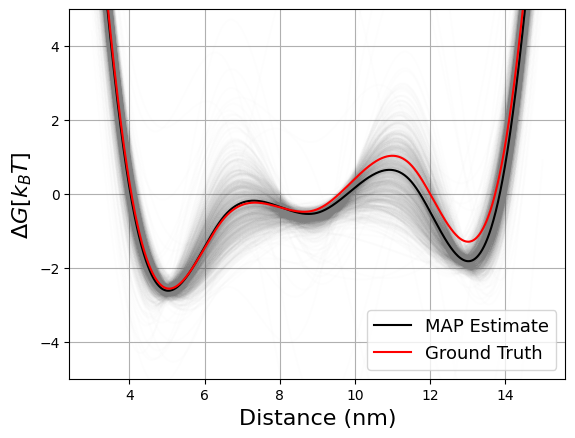

In [42]:
for i in range(1000):
    x, y = eval_spline(
        params=samples[i],
        x_eval=np.linspace(3, 15, 1000),
    )
    plt.plot(x, y, color='gray', alpha=0.01)
x, y = eval_spline(
    params=map_estimate[0].cpu(),
    x_eval=np.linspace(3, 15, 1000),
)
plt.plot(x, y, color='black', label='MAP Estimate')
x, y = eval_spline(
    params=true_params,
    x_eval=np.linspace(3, 15, 1000),
)
plt.plot(x, y+0., color='r', label='Ground Truth')
plt.xlabel("Distance (nm)", fontsize=16)
plt.ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
plt.ylim(-5, 5)
plt.grid()
plt.legend(fontsize=13)

Text(0, 0.5, 'p(log(D)|x)')

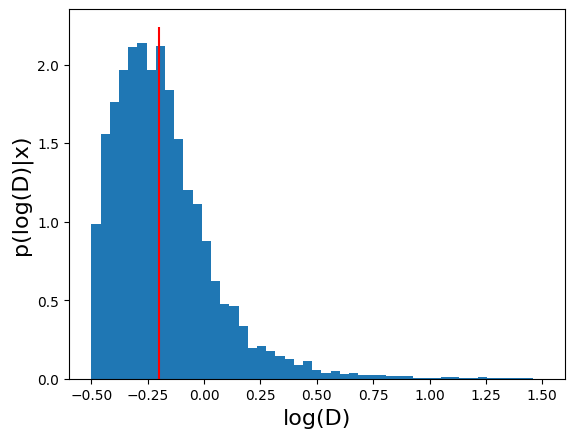

In [43]:
plt.hist(samples[:, 0].numpy(), bins=np.linspace(-0.5, 1.5, 50), density=True)
plt.vlines(true_params[0], ymin=0, ymax=plt.gca().get_ylim()[1], color='r', label='Ground Truth')
plt.xlabel("log(D)", fontsize=16)
plt.ylabel("p(log(D)|x)", fontsize=16)